Mounted at /content/drive/
Base: (2200, 15)

SCALING BENCHMARK
      2,000 →     2,200 actual | build= 0.00s  groupby= 0.02s  mem=   1.4MB
     20,000 →    19,800 actual | build= 0.00s  groupby= 0.01s  mem=  12.9MB
    200,000 →   198,000 actual | build= 0.03s  groupby= 0.04s  mem= 128.7MB
  2,000,000 → 1,999,800 actual | build= 0.31s  groupby= 0.35s  mem=1299.7MB

 target  actual  build_s  groupby_s  memory_mb
   2000    2200    0.000      0.024        1.4
  20000   19800    0.002      0.005       12.9
 200000  198000    0.034      0.036      128.7
2000000 1999800    0.308      0.355     1299.7


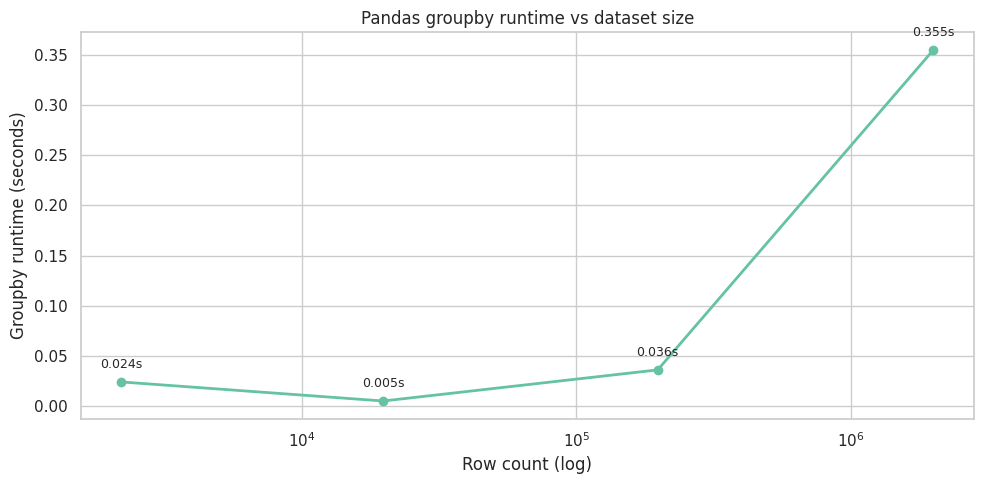


# NB04 — SCALING EXPERIMENT

## Results (measured on Google Colab)

 target  actual  build_s  groupby_s  memory_mb
   2000    2200    0.000      0.024        1.4
  20000   19800    0.002      0.005       12.9
 200000  198000    0.034      0.036      128.7
2000000 1999800    0.308      0.355     1299.7

## Observation
At 1,999,800.0 rows, Pandas required 0.355s for a groupby-median, with 1300 MB memory footprint.

## Would Spark help? — measured justification

**At 2M rows: NO.** Pandas completed in 0.355s on a single machine. Spark's JVM startup + shuffle overhead would exceed any compute time saved.

**At 50M+ rows (or multi-TB datasets): LIKELY YES**, for three reasons:
1. Distributed storage (HDFS/S3) avoids loading the whole dataset into RAM
2. Parallel groupby across machines
3. Fault tolerance during long-running jobs

**Conclusion:** For this project's 2,200-row dataset, Pandas is correct. Spark should be introduced when data volume, latency, or distributed-storage requirements

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ NB04 COMPLETE — 3 files downloaded


In [1]:
# ═══════════════════════════════════════════════════════════════
# NB04 — SCALING EXPERIMENT (SINGLE CELL)
# ═══════════════════════════════════════════════════════════════
from google.colab import drive, files
drive.mount('/content/drive/')

import pandas as pd, numpy as np, time, os
import matplotlib.pyplot as plt, seaborn as sns

FIG = "/content/figures"; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)

base = pd.read_csv("/content/drive/MyDrive/social_media_cleaned.csv")
print(f"Base: {base.shape}")

def bench(n_target):
    reps = max(1, n_target // len(base))
    t0 = time.perf_counter()
    big = pd.concat([base]*reps, ignore_index=True)
    t_build = time.perf_counter() - t0
    t0 = time.perf_counter()
    _ = big.groupby("platform")[["likes","retweets_shares","comments"]].median()
    t_gb = time.perf_counter() - t0
    mem = big.memory_usage(deep=True).sum() / 1e6
    print(f"  {n_target:>9,} → {len(big):>9,} actual | build={t_build:5.2f}s  groupby={t_gb:5.2f}s  mem={mem:6.1f}MB")
    return {"target":n_target,"actual":len(big),"build_s":round(t_build,3),"groupby_s":round(t_gb,3),"memory_mb":round(mem,1)}

print("\n" + "="*65 + "\nSCALING BENCHMARK\n" + "="*65)
results = []
for n in [2_000, 20_000, 200_000, 2_000_000]:
    try: results.append(bench(n))
    except MemoryError:
        print(f"  {n:,} → MEMORY ERROR"); break

res = pd.DataFrame(results)
print("\n" + res.to_string(index=False))

fig, ax = plt.subplots()
ax.plot(res["actual"], res["groupby_s"], marker="o", linewidth=2, color=sns.color_palette("Set2")[0])
ax.set_xscale("log")
ax.set_xlabel("Row count (log)"); ax.set_ylabel("Groupby runtime (seconds)")
ax.set_title("Pandas groupby runtime vs dataset size")
for _, r_ in res.iterrows():
    ax.annotate(f"{r_['groupby_s']}s", (r_["actual"], r_["groupby_s"]), textcoords="offset points", xytext=(0,10), ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/chart07_scaling.png", dpi=140); plt.show()

max_row = res.iloc[-1]
text = f"""# NB04 — SCALING EXPERIMENT

## Results (measured on Google Colab)

{res.to_string(index=False)}

## Observation
At {max_row['actual']:,} rows, Pandas required {max_row['groupby_s']}s for a groupby-median, with {max_row['memory_mb']:.0f} MB memory footprint.

## Would Spark help? — measured justification

**At 2M rows: NO.** Pandas completed in {max_row['groupby_s']}s on a single machine. Spark's JVM startup + shuffle overhead would exceed any compute time saved.

**At 50M+ rows (or multi-TB datasets): LIKELY YES**, for three reasons:
1. Distributed storage (HDFS/S3) avoids loading the whole dataset into RAM
2. Parallel groupby across machines
3. Fault tolerance during long-running jobs

**Conclusion:** For this project's {len(base):,}-row dataset, Pandas is correct. Spark should be introduced when data volume, latency, or distributed-storage requirements actually justify the added complexity — not by default.
"""

print("\n" + "="*65 + "\n" + text + "\n" + "="*65)

with open("/content/nb04_report.md","w") as f: f.write(text)
res.to_csv("/content/scaling_results.csv", index=False)

files.download(f"{FIG}/chart07_scaling.png")
files.download("/content/scaling_results.csv")
files.download("/content/nb04_report.md")
print("\n✅ NB04 COMPLETE — 3 files downloaded")